# Задача 4. Распределения собранного заряда

Используем классы `Detector` (задачи 1, 3) и `Source` (задача 2). Функция `simulate_charge` из `src/simulation.py` возвращает заряды по каналам для серии событий, массив `(n_events, N)`; полный заряд — сумма по каналам. Число фотонов здесь фиксировано: $n = YE$ (случайным оно станет в задаче 5).

In [1]:
import sys
sys.path.insert(0, '../src')   # код проекта
import numpy as np
import matplotlib.pyplot as plt
from detector import Detector
from source import Source
from simulation import simulate_charge, expected_fraction

det = Detector(R=2.0, N=40, r=0.10, a=0.5, rng=4)
src = Source(Y=10_000, rng=40)
n_events = 1000

## 1000 событий, E = 1 МэВ, центр

Ожидание: $\langle Q\rangle = aYE\,f$, где $f$ — доля фотонов, попавших на катоды. Здесь $f$ считается в приближении малого диска (`expected_fraction`): в центре оно на 0.2% выше точного телесного угла, поэтому ожидание равно 125.3, а не 125.1 как в задаче 3. На катоды попадает биномиальное число фотонов с вероятностью $f$, каждый фотон даёт Пуассон$(a)$ ф.э.:
$$\sigma_Q^2 = \langle Q\rangle (1 + a(1-f))\quad\Rightarrow\quad \frac{\sigma_Q}{\langle Q\rangle} = \sqrt{\frac{1+a(1-f)}{aYfE}}\propto \frac{1}{\sqrt E}.$$

<Q> = 125.55 ± 0.44   ожидание 125.31
σ_Q = 14.02   ожидание 13.65


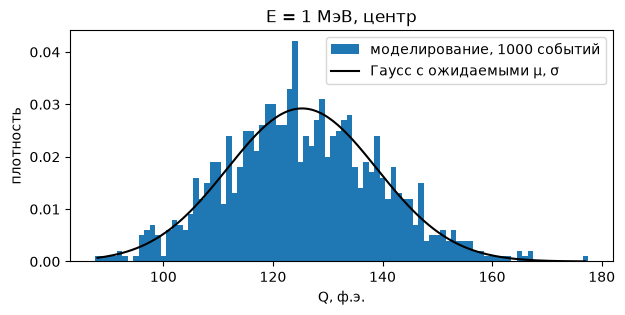

In [2]:
Q1 = simulate_charge(det, src, 1.0, n_events=n_events, fluctuate=False).sum(axis=1)
f0 = expected_fraction(det).sum()
Qexp = det.a * src.Y * 1.0 * f0
print(f"<Q> = {Q1.mean():.2f} ± {Q1.std()/np.sqrt(n_events):.2f}   ожидание {Qexp:.2f}")
print(f"σ_Q = {Q1.std():.2f}   ожидание {np.sqrt(Qexp*(1+det.a*(1-f0))):.2f}")

bins = np.arange(Q1.min() - 0.5, Q1.max() + 1.5)
plt.figure(figsize=(7, 3))
plt.hist(Q1, bins=bins, density=True, label='моделирование, 1000 событий')
x = np.linspace(Q1.min(), Q1.max(), 200)
s = np.sqrt(Qexp * (1 + det.a * (1 - f0)))
plt.plot(x, np.exp(-(x - Qexp)**2 / (2*s**2)) / (np.sqrt(2*np.pi)*s), 'k', label='Гаусс с ожидаемыми μ, σ')
plt.xlabel('Q, ф.э.'); plt.ylabel('плотность'); plt.title('E = 1 МэВ, центр'); plt.legend(); plt.show()

## Зависимость от энергии

In [3]:
energies = np.array([0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0])
Q = {E: (Q1 if E == 1.0 else simulate_charge(det, src, E, n_events=n_events, fluctuate=False).sum(axis=1))
     for E in energies}

mean = np.array([Q[E].mean() for E in energies])
std = np.array([Q[E].std() for E in energies])
rel = std / mean
rel_err = rel / np.sqrt(2 * (n_events - 1))          # ошибка оценки σ ≈ σ/sqrt(2n)
rel_theory = np.sqrt((1 + det.a * (1 - f0)) / (det.a * src.Y * f0 * energies))

print(" E, МэВ   <Q>      σ_Q    σ/<Q>    теория")
for E, m_, s_, r_, t_ in zip(energies, mean, std, rel, rel_theory):
    print(f"{E:6.1f} {m_:8.1f} {s_:7.2f} {r_:8.4f} {t_:8.4f}")

 E, МэВ   <Q>      σ_Q    σ/<Q>    теория
   0.2     25.0    6.07   0.2431   0.2436
   0.5     62.4    9.37   0.1502   0.1541
   0.7     87.8   11.30   0.1286   0.1302
   1.0    125.5   14.02   0.1117   0.1089
   1.5    188.3   17.08   0.0907   0.0890
   2.0    250.5   19.88   0.0794   0.0770
   3.0    375.6   23.59   0.0628   0.0629


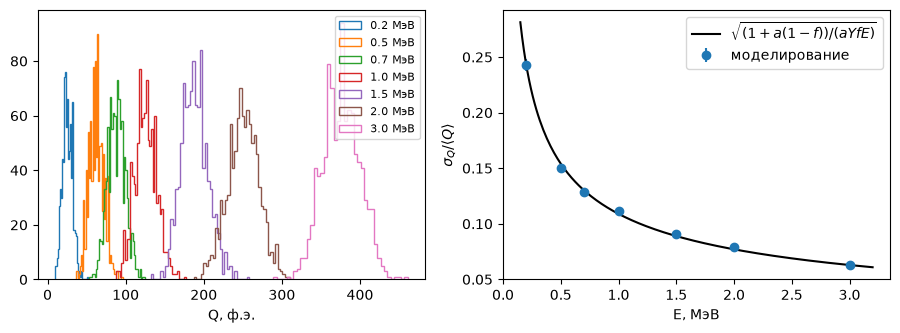

σ/<Q> ∝ E^p,  p = -0.489  (ожидается -0.5);  при 1 МэВ: 0.1095


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for E in energies:
    ax[0].hist(Q[E], bins=40, histtype='step', label=f'{E} МэВ')
ax[0].set_xlabel('Q, ф.э.'); ax[0].legend(fontsize=8)

ax[1].errorbar(energies, rel, rel_err, fmt='o', label='моделирование')
Eg = np.linspace(0.15, 3.2, 200)
ax[1].plot(Eg, np.sqrt((1 + det.a * (1 - f0)) / (det.a * src.Y * f0 * Eg)), 'k',
           label=r'$\sqrt{(1+a(1-f))/(aYfE)}$')
ax[1].set_xlabel('E, МэВ'); ax[1].set_ylabel(r'$\sigma_Q/\langle Q\rangle$'); ax[1].legend()
plt.show()

# аппроксимация степенной функцией: σ/Q = A E^p
p, logA = np.polyfit(np.log(energies), np.log(rel), 1)
print(f"σ/<Q> ∝ E^p,  p = {p:.3f}  (ожидается -0.5);  при 1 МэВ: {np.exp(logA):.4f}")

**Вывод.** Относительная ширина падает как $1/\sqrt E$: число фотоэлектронов растёт линейно с энергией, а флуктуации пуассоновские. При $a = 0.5$ ширина дополнительно увеличена в $\sqrt{1+a(1-f)}\approx 1.22$ раза из-за флуктуаций числа ф.э. на фотон. Энергетическое разрешение детектора $\approx 11\%/\sqrt{E[\text{МэВ}]}$.

## Источник смещён на 1 м по оси z

Для точки вне центра доли фотонов на отдельные ФЭУ меняются: ближние катоды видны под большим телесным углом ($\propto \cos\psi/d^2$), дальние — под меньшим. Для **сплошного** покрытия эти изменения в точности компенсируют друг друга (теорема Гаусса: $\oint \cos\psi\, dA/d^2 = 4\pi$ для любой точки внутри), поэтому полный заряд не изменился бы. Для 40 дискретных ФЭУ компенсация неполная, и изменение зависит от того, как ФЭУ расположены относительно источника.

центр:  <Q> = 125.55 ± 0.44   (ожидание 125.31)
z=1 м:  <Q> = 124.71 ± 0.43   (ожидание 125.18)
изменение: моделирование -0.67% ± 0.49%,  ожидание -0.10%


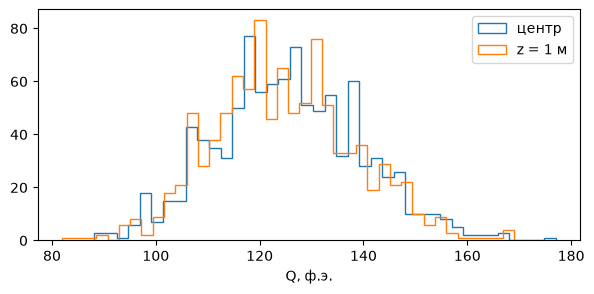

In [5]:
origin = (0, 0, 1.0)
Q1z = simulate_charge(det, src, 1.0, origin=origin, n_events=n_events, fluctuate=False).sum(axis=1)
f1 = expected_fraction(det, origin).sum()
d_mc = Q1z.mean() / Q1.mean() - 1
d_mc_err = np.sqrt((Q1z.std()/Q1z.mean())**2 + (Q1.std()/Q1.mean())**2) / np.sqrt(n_events)
print(f"центр:  <Q> = {Q1.mean():.2f} ± {Q1.std()/np.sqrt(n_events):.2f}   (ожидание {det.a*src.Y*f0:.2f})")
print(f"z=1 м:  <Q> = {Q1z.mean():.2f} ± {Q1z.std()/np.sqrt(n_events):.2f}   (ожидание {det.a*src.Y*f1:.2f})")
print(f"изменение: моделирование {d_mc:+.2%} ± {d_mc_err:.2%},  ожидание {f1/f0 - 1:+.2%}")

plt.figure(figsize=(7, 3))
plt.hist(Q1, bins=40, histtype='step', label='центр')
plt.hist(Q1z, bins=40, histtype='step', label='z = 1 м')
plt.xlabel('Q, ф.э.'); plt.legend(); plt.show()

Распределение заряда по каналам при этом меняется сильно — это и позволяет восстанавливать положение вершины:

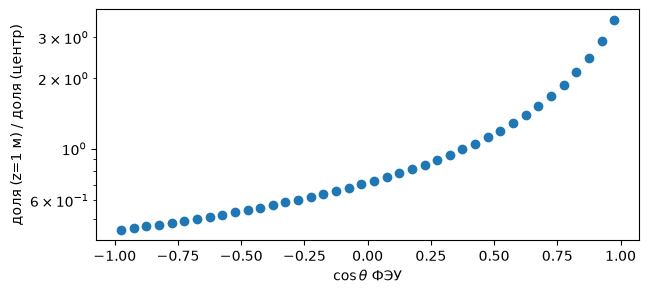

от 0.45 до 3.56


In [6]:
fz = expected_fraction(det, origin)
fc = expected_fraction(det)
cos_theta = det.pmt_directions[:, 2]
plt.figure(figsize=(7, 3))
plt.plot(cos_theta, fz / fc, 'o')
plt.xlabel(r'$\cos\theta$ ФЭУ'); plt.ylabel('доля (z=1 м) / доля (центр)')
plt.yscale('log'); plt.show()
print(f"от {(fz/fc).min():.2f} до {(fz/fc).max():.2f}")

изменение <Q> для смещения на 1 м: среднее +0.00%, разброс 0.32%, от -1.32% до +0.76%


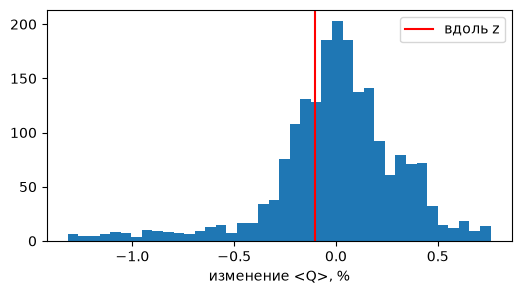

In [7]:
# насколько изменение среднего зависит от направления смещения (1 м в разные стороны)
from detector import fibonacci_sphere
shifts = fibonacci_sphere(2000)
rel_change = np.array([expected_fraction(det, s).sum() for s in shifts]) / f0 - 1
print(f"изменение <Q> для смещения на 1 м: среднее {rel_change.mean():+.2%}, "
      f"разброс {rel_change.std():.2%}, от {rel_change.min():+.2%} до {rel_change.max():+.2%}")
plt.figure(figsize=(6, 3)); plt.hist(rel_change * 100, bins=40)
plt.axvline((f1/f0 - 1) * 100, color='r', label='вдоль z'); plt.legend()
plt.xlabel('изменение <Q>, %'); plt.show()

Повторим всю серию энергий для источника в точке $z = 1$ м.

 E, МэВ  <Q> центр  <Q> z=1 м   изменение      σ/<Q> центр  σ/<Q> z=1 м
   0.2       25.0       24.8   -0.66% ± 1.08%       0.2431       0.2412
   0.5       62.4       62.5   +0.18% ± 0.67%       0.1502       0.1506
   0.7       87.8       87.5   -0.37% ± 0.58%       0.1286       0.1296
   1.0      125.5      124.7   -0.67% ± 0.49%       0.1117       0.1095
   1.5      188.3      187.4   -0.46% ± 0.40%       0.0907       0.0898
   2.0      250.5      249.0   -0.57% ± 0.35%       0.0794       0.0776
   3.0      375.6      374.5   -0.31% ± 0.28%       0.0628       0.0622

по всем энергиям: -0.42% ± 0.16%,  ожидание -0.10%


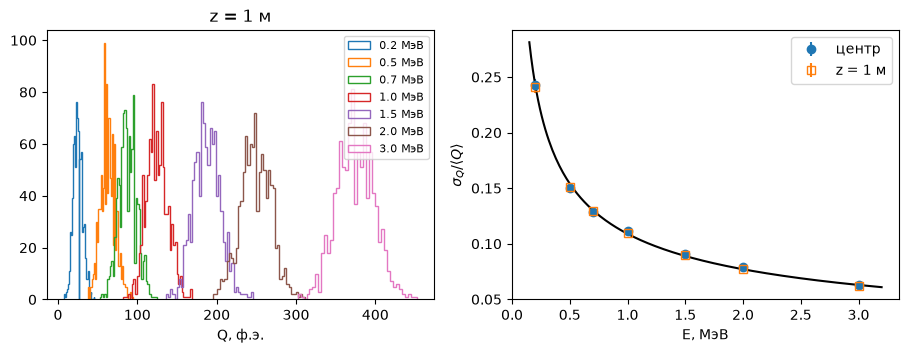

In [8]:
Qz = {E: (Q1z if E == 1.0 else simulate_charge(det, src, E, origin=origin, n_events=n_events, fluctuate=False).sum(axis=1))
      for E in energies}
print(" E, МэВ  <Q> центр  <Q> z=1 м   изменение      σ/<Q> центр  σ/<Q> z=1 м")
for E in energies:
    q0, q1 = Q[E], Qz[E]
    d = q1.mean() / q0.mean() - 1
    e = np.sqrt((q1.std()/q1.mean())**2 + (q0.std()/q0.mean())**2) / np.sqrt(n_events)
    print(f"{E:6.1f} {q0.mean():10.1f} {q1.mean():10.1f}   {d:+6.2%} ± {e:.2%} {q0.std()/q0.mean():12.4f} {q1.std()/q1.mean():12.4f}")

all_E = np.sum([Qz[E].sum() for E in energies]) / np.sum([Q[E].sum() for E in energies]) - 1
all_err = np.sqrt(2 * (1 + det.a) / np.sum([Q[E].sum() for E in energies]))
print(f"\nпо всем энергиям: {all_E:+.2%} ± {all_err:.2%},  ожидание {f1/f0 - 1:+.2%}")

rel_z = np.array([Qz[E].std() / Qz[E].mean() for E in energies])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for E in energies:
    ax[0].hist(Qz[E], bins=40, histtype='step', label=f'{E} МэВ')
ax[0].set_xlabel('Q, ф.э.'); ax[0].set_title('z = 1 м'); ax[0].legend(fontsize=8)
ax[1].errorbar(energies, rel, rel_err, fmt='o', label='центр')
ax[1].errorbar(energies, rel_z, rel_err, fmt='s', mfc='none', label='z = 1 м')
ax[1].plot(Eg, np.sqrt((1 + det.a * (1 - f0)) / (det.a * src.Y * f0 * Eg)), 'k')
ax[1].set_xlabel('E, МэВ'); ax[1].set_ylabel(r'$\sigma_Q/\langle Q\rangle$'); ax[1].legend()
plt.show()

**Выводы.**
- При $E = 1$ МэВ в центре $\langle Q\rangle = 125.6 \pm 0.4$ ф.э. при ожидании 125.3, $\sigma_Q = 14.0$ при ожидании 13.65.
- Относительная ширина падает как $1/\sqrt E$: подгонка даёт показатель $p = -0.489$, а $\sigma_Q/\langle Q\rangle \approx 11\%$ при 1 МэВ.
- Смещение источника на 1 м по оси $z$ почти не меняет средний заряд: $-0.67\% \pm 0.49\%$ при 1 МэВ и $-0.42\% \pm 0.16\%$ по всем энергиям при ожидании $-0.10\%$. Расхождение на $2\sigma$ оказалось флуктуацией: в отдельном расчёте на $10^5$ событиях при 1 МэВ изменение равно $-0.120\% \pm 0.049\%$. Относительная ширина остаётся той же в пределах статистики.
- Для других направлений смещения на 1 м ожидаемое изменение лежит в пределах от $-1.3\%$ до $+0.8\%$ из-за дискретного расположения ФЭУ. Заряды отдельных каналов при этом меняются сильно, от 0.45 до 3.56 раза.